# 05b — Staggered-Adoption Event Study

**Project:** Causal ML for Climate Policy Effectiveness  
**Purpose:** Formal parallel-trends test and dynamic treatment-effect path, using a Sun & Abraham (2021) interaction-weighted event-study estimator  
**Input:** `data/processed/analysis_panel.csv`  
**Output:** Event-study coefficient tables and figures (per treatment type)

---

The cross-sectional DML/Causal Forest analysis in Notebook 05 identifies effects
under an unconfoundedness/overlap assumption (treatment as-good-as-random given
observed covariates). This notebook adds a complementary, genuinely dynamic
design: for each country, event time is defined relative to its **own** policy
adoption year, and effects are estimated separately by cohort x event-time
before being aggregated (Sun-Abraham), using never-treated countries as the
comparison group throughout. This avoids the "forbidden comparison" problem of
naive dynamic two-way-fixed-effects under staggered adoption (Goodman-Bacon, 2021).

The pre-treatment leads provide the paper's first formal test of the
parallel-trends assumption -- something the prior binary cross-sectional design
had no equivalent for. This replaces a prior `event_study.png`/`temporal_dynamics.csv`
that had no traceable generating code anywhere in the repository.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.event_study import run_event_study, pretrend_test
from src.visualization import set_publication_style, save_figure, COLORS

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
set_publication_style()

In [2]:
panel = pd.read_csv(PROCESSED_DIR / "analysis_panel.csv")
print(f"Panel: {panel.shape[0]:,} rows x {panel.shape[1]} columns")

OUTCOME = "log_co2"
COVARIATES = [c for c in ["population", "gdp_per_capita", "urban_pct"] if c in panel.columns]
TREATMENTS = [c for c in panel.columns if c.startswith("treat_") and panel[c].std() > 0]
print(f"Treatments: {TREATMENTS}")
print(f"Covariates: {COVARIATES}")

Panel: 7,630 rows x 74 columns
Treatments: ['treat_carbon_pricing', 'treat_renewable_mandate', 'treat_efficiency_standard']
Covariates: ['population', 'gdp_per_capita', 'urban_pct']


---
## 5b.1 — Event Study by Treatment Type

In [3]:
WINDOW = (-5, 5)
all_event_results = {}
pretrend_summary = []

for treat in TREATMENTS:
    print("=" * 60)
    print(f"Event study: {treat}")
    print("=" * 60)
    try:
        res = run_event_study(
            panel, treat, OUTCOME,
            covariate_cols=COVARIATES, window=WINDOW,
        )
        all_event_results[treat] = res
        print(res.to_string(index=False))

        pt = pretrend_test(res)
        pt["treatment"] = treat
        pretrend_summary.append(pt)
        print(f"\nPer-coefficient screen: {pt['n_significant']}/{pt['n_pretrend_periods']} "
              f"pre-treatment leads individually significant")
        print(f"Joint Wald test (all pre-treatment leads = 0): "
              f"chi2={pt['joint_chi2']:.2f}, df={pt['joint_df']}, p={pt['joint_p_value']:.4f} "
              f"-> {'PASSES' if pt['joint_test_passes'] else 'FAILS'} at the 5% level")
        print("(The joint test is the actual parallel-trends check; the per-coefficient "
              "screen alone can miss a jointly significant departure from zero.)")

        res.to_csv(TABLE_DIR / f"event_study_{treat}.csv", index=False)
    except Exception as e:
        print(f"  FAILED: {e}")
    print()

Event study: treat_carbon_pricing


 event_time  estimate  std_error  ci_lower  ci_upper      p_value  n_cohorts
         -5  0.049202   0.036048 -0.021450  0.119855 1.722810e-01         22
         -4  0.044163   0.019227  0.006479  0.081848 2.162399e-02         22
         -3  0.020905   0.013235 -0.005035  0.046846 1.142185e-01         22
         -2  0.006699   0.007620 -0.008235  0.021633 3.793294e-01         22
         -1  0.000000   0.000000  0.000000  0.000000          NaN         24
          0  0.005123   0.006519 -0.007655  0.017900 4.320124e-01         24
          1  0.004750   0.008653 -0.012209  0.021709 5.830389e-01         23
          2 -0.014412   0.011514 -0.036979  0.008154 2.106689e-01         22
          3 -0.023383   0.015310 -0.053390  0.006623 1.266777e-01         21
          4 -0.050186   0.016515 -0.082555 -0.017816 2.375646e-03         19
          5 -0.420420   0.040731 -0.500252 -0.340589 5.616975e-25         18

Per-coefficient screen: 1/4 pre-treatment leads individually significant
Jo

 event_time  estimate  std_error  ci_lower  ci_upper  p_value  n_cohorts
         -5  0.084747   0.046099 -0.005605  0.175098 0.066007         25
         -4  0.042901   0.016101  0.011344  0.074457 0.007709         26
         -3  0.038997   0.013838  0.011875  0.066119 0.004831         26
         -2  0.027428   0.010221  0.007395  0.047460 0.007286         26
         -1  0.000000   0.000000  0.000000  0.000000      NaN         27
          0 -0.008913   0.007933 -0.024461  0.006636 0.261241         27
          1 -0.010575   0.011721 -0.033548  0.012398 0.366946         27
          2 -0.018253   0.016422 -0.050439  0.013933 0.266348         27
          3 -0.020059   0.020078 -0.059411  0.019293 0.317776         27
          4 -0.007151   0.023242 -0.052705  0.038403 0.758337         26
          5 -0.182702   0.049054 -0.278845 -0.086558 0.000196         25

Per-coefficient screen: 3/4 pre-treatment leads individually significant
Joint Wald test (all pre-treatment leads = 0): chi

 event_time  estimate  std_error  ci_lower  ci_upper      p_value  n_cohorts
         -5  0.114778   0.044182  0.028183  0.201374 9.381538e-03         24
         -4  0.057395   0.016471  0.025113  0.089678 4.928522e-04         25
         -3  0.060724   0.014854  0.031610  0.089838 4.351295e-05         25
         -2  0.033349   0.012067  0.009699  0.057000 5.714593e-03         25
         -1  0.000000   0.000000  0.000000  0.000000          NaN         26
          0 -0.020904   0.009718 -0.039952 -0.001857 3.147314e-02         26
          1 -0.043251   0.013635 -0.069976 -0.016526 1.514116e-03         25
          2 -0.039947   0.014237 -0.067850 -0.012044 5.017325e-03         25
          3 -0.041004   0.017472 -0.075247 -0.006760 1.893145e-02         25
          4 -0.059789   0.019396 -0.097805 -0.021773 2.052628e-03         25
          5 -0.372314   0.041395 -0.453446 -0.291181 2.380240e-19         25

Per-coefficient screen: 4/4 pre-treatment leads individually significant
Jo

---
## 5b.2 — Event-Study Plot (Primary Treatment: Carbon Pricing)

  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\event_study.png


  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\event_study.pdf


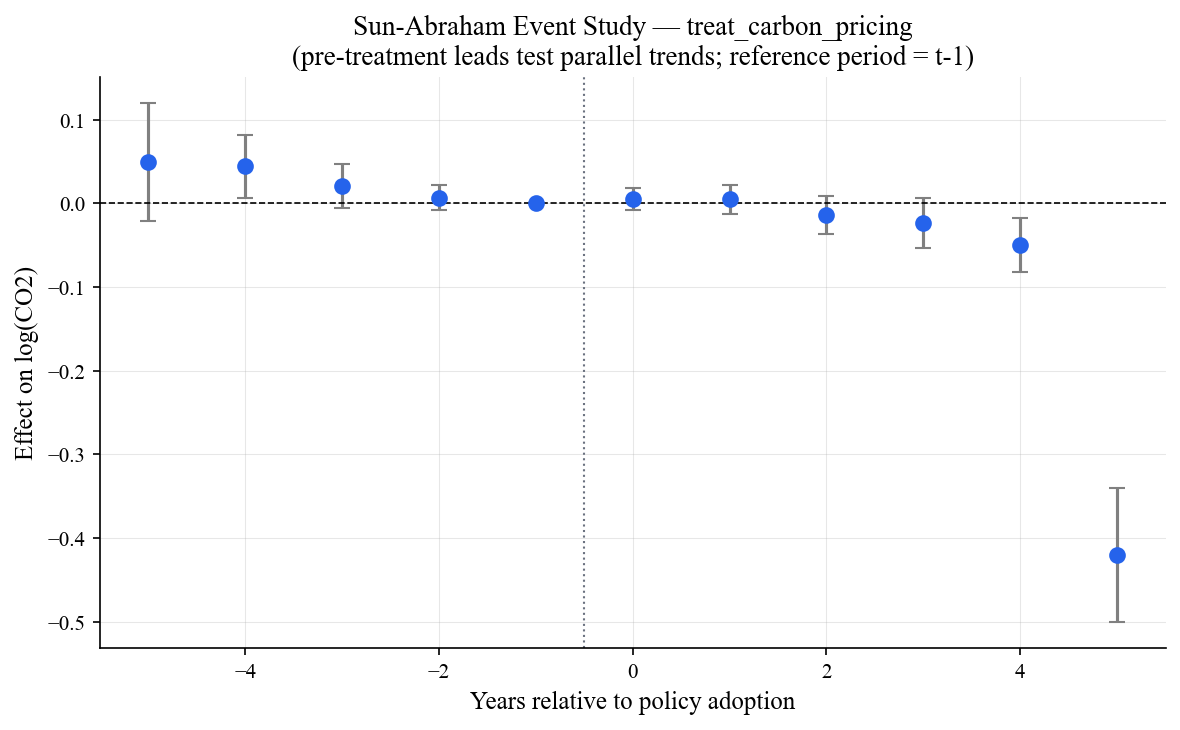

In [4]:
primary_treat = "treat_carbon_pricing" if "treat_carbon_pricing" in all_event_results else TREATMENTS[0]

if primary_treat in all_event_results:
    res = all_event_results[primary_treat]

    fig, ax = plt.subplots(figsize=(8, 5))
    colors = [COLORS["danger"] if t < 0 else COLORS["primary"] for t in res["event_time"]]
    ax.errorbar(
        res["event_time"], res["estimate"],
        yerr=[res["estimate"] - res["ci_lower"], res["ci_upper"] - res["estimate"]],
        fmt="o", capsize=4, color=COLORS["primary"], markersize=7, ecolor="gray",
    )
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.axvline(-0.5, color=COLORS["neutral"], linestyle=":", linewidth=1)
    ax.set_xlabel("Years relative to policy adoption")
    ax.set_ylabel("Effect on log(CO2)")
    ax.set_title(f"Sun-Abraham Event Study — {primary_treat}\n"
                 "(pre-treatment leads test parallel trends; reference period = t-1)")
    plt.tight_layout()
    save_figure(fig, "event_study")
    plt.show()
else:
    print("No event-study results available to plot.")

---
## 5b.3 — Cross-Check Against Cross-Sectional DML/CF Estimates

In [5]:
print("=" * 60)
print("5b.3 - Pre-trend summary and cross-check")
print("=" * 60)

pretrend_df = pd.DataFrame(pretrend_summary)
print(pretrend_df.to_string(index=False))
pretrend_df.to_csv(TABLE_DIR / "event_study_pretrend_summary.csv", index=False)

if primary_treat in all_event_results:
    res = all_event_results[primary_treat]
    post = res[res["event_time"] >= 0]
    avg_post_effect = post["estimate"].mean()
    print(f"\nAverage post-adoption event-study effect ({primary_treat}): {avg_post_effect:+.4f}")
    print("Compare to Notebook 05's DML/Causal Forest ATE for the same treatment: if signs\n"
          "disagree, this is a genuine finding about design sensitivity (unconfoundedness\n"
          "cross-section vs. own-adoption-year dynamic design) that must be discussed in the\n"
          "manuscript, not silently reconciled.")

print("\n Event study complete")
print("  Proceed to Notebook 06: Robustness Checks")

5b.3 - Pre-trend summary and cross-check
 n_pretrend_periods  n_significant  all_insignificant  joint_chi2  joint_df  joint_p_value  joint_test_passes                 treatment
                  4              1              False    5.882244         4       0.208117               True      treat_carbon_pricing
                  4              3              False    8.353617         4       0.079451               True   treat_renewable_mandate
                  4              4              False   18.942791         4       0.000807              False treat_efficiency_standard

Average post-adoption event-study effect (treat_carbon_pricing): -0.0831
Compare to Notebook 05's DML/Causal Forest ATE for the same treatment: if signs
disagree, this is a genuine finding about design sensitivity (unconfoundedness
cross-section vs. own-adoption-year dynamic design) that must be discussed in the
manuscript, not silently reconciled.

 Event study complete
  Proceed to Notebook 06: Robustness Che